# My Question:
# Uno | What is the union probability of drawing a wild 4+ card OR a green card in an uno stack for the first card?

# Simulation Description:
### The random process I am simulating is a person grabbing a card in a random uno stack to create the pile for the first player.
### In one trial, the card that will be first drawn would be a number card(in the 4 colors), action cards(in the four colors), wild cards, or wild +4 cards.
### The compound event I will be measuring is the probability that the first card drawn from an uno stack is a green card(B) OR a wild 4+ card(A). The outcomes that represent this event is a green card or a wild draw four card being drawn as the first card.

# More Details:

### A and B are mutually exclusive because these events cannot happen at the same time(only one card is being drawn). The question is asking for union probability which is based on the probability of A and B together. 
###  A and B are dependent because if a Wild card +4 is drawn as the first card that means that the probability of B(green card) being pulled is non-existent since we are measuring the outcome through one card. Since A being drawn impact's B's chance of being drawn and vice versa these two events are dependent not independent. 

# Analysis: 

In [11]:
# theoretical probability: favorable outcomes/total possible outcomes  P(A) + P(B)/108    
# empirical probability: number of times event occurred/ total number of trials or # of green and # or wild +4/100

In [32]:
import numpy as np
import pandas as pd

In [33]:
colors = ['Red', 'Yellow', 'Blue', 'Green']
deck = []

In [34]:
for color in colors:
    deck.append({'color': color, 'type': '0'})
    for num in range(1, 10):
        deck.append({'color': color, 'type': str(num)})
        deck.append({'color': color, 'type': str(num)})
    for action in ['Skip', 'Reverse', 'Draw Two']:
        deck.append({'color': color, 'type': action})
        deck.append({'color': color, 'type': action})

In [35]:
for _ in range(4):
    deck.append({'color': 'Wild', 'type': 'Wild'})
    deck.append({'color': 'Wild', 'type': 'Wild Draw 4'})

df_deck = pd.DataFrame(deck)

In [36]:
total_cards = len(df_deck)
green_cards = len(df_deck[df_deck['color'] == 'Green'])
wild_4_cards = len(df_deck[df_deck['type'] == 'Wild Draw 4'])

In [37]:
prob_theoretical = (green_cards + wild_4_cards) / total_cards

In [38]:
N = 1_080_000
np.random.seed(42)

In [39]:
samples = df_deck.sample(n=N, replace=True, random_state=42).reset_index(
    drop=True
)

In [40]:
wild_plus_4 = samples['type'] == 'Wild Draw 4'
green = samples['color'] == 'Green'
firstdraws = wild_plus_4 | green

In [41]:
simprob = firstdraws.mean()

In [42]:
print(f"Simulated Union Probability: {simprob:.6f}")
print(f"Theoretical Probability:     {prob_theoretical:.6f}")
print(f"Empirical Probability:   {prob_empirical:.6f} (from {N:,} trials)")

Simulated Union Probability: 0.268894
Theoretical Probability:     0.268519
Empirical Probability:   0.240000 (from 1,080,000 trials)


# Conclusion: 
##  The union probability of a person drawing a green card or a wild +4 card for the first card in an uno stack is 0.268519 which was calculated by theoretical probability. The empirical probability which was calculated from the results of the simulation was  0.24. The graph below supports my answer because it shows the theoretical probability and shows how the empirical probability varies at the start of the simulation but converges with the theoretical probability line at the end of the simulation. This shows how the probabilities are same/similar for this question if it was tested in a simulation.

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
cumulative_draws = np.cumsum(firstdraws)
trial_numbers = np.arange(1, N + 1)
running_probabilities = cumulative_draws / trial_numbers

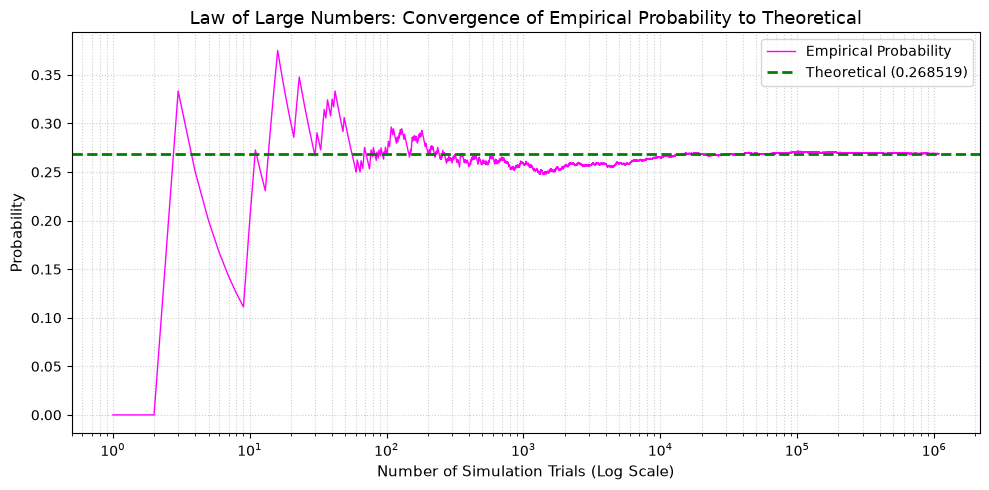

In [47]:
plt.figure(figsize=(10, 5))
plt.plot(
    trial_numbers,
    running_probabilities,
    color='magenta',
    linewidth=1,
    label='Empirical Probability',
)
plt.axhline(
    y=prob_theoretical,
    color='green',
    linestyle='--',
    linewidth=2,
    label=f'Theoretical ({prob_theoretical:.6f})',
)

plt.xscale('log')  
plt.title(
    'Law of Large Numbers: Convergence of Empirical Probability to Theoretical',
    fontsize=13,
)
plt.xlabel('Number of Simulation Trials (Log Scale)', fontsize=11)
plt.ylabel('Probability', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, which='both', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()